In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# Step 1: Create a simple binary classification dataset
x = np.array([1, 2, 3, 4, 5, 6])
y = np.array([0, 0, 0, 1, 1, 1])  # Target: 0 if x < 4, else 1

In [3]:
# Normalize x for better training (optional, but helps)
# x = (x - np.mean(x)) / np.std(x) # for making the datas small

# see the below output all the datas are converted to -2 to 2
x

array([1, 2, 3, 4, 5, 6])

In [4]:
# Step 2: Define sigmoid and prediction functions
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def predict(x, w1, w0):
    z = w1 * x + w0
    return sigmoid(z)

In [5]:
e = 1e-15

test = np.clip(predict(x, 0, 1000), e, 1 - e)

test

array([1., 1., 1., 1., 1., 1.])

In [6]:
# Step 3: Define binary cross-entropy loss
def binary_cross_entropy(y_true, y_pred):
    epsilon = 1e-15  # for numerical stability
    y_pred = np.clip(y_pred, epsilon, 1 - epsilon)
    return -np.mean(y_true * np.log(y_pred) + (1 - y_true) * np.log(1 - y_pred))

In [7]:
# Step 4: Initialize weights and training params

w1, w0 = 0.0, 0.0 # weigth and bais
lr = 0.1 # Learning rate

epochs = 1000

losses = [] # use matplotlib for Visualization

In [8]:
# Step 5: Gradient Descent Training Loop
for epoch in range(epochs):
    y_pred = predict(x, w1, w0)
    loss = binary_cross_entropy(y, y_pred)
    losses.append(loss)

    # Gradients
    dw1 = np.dot((y_pred - y), x) / len(x)
    dw0 = np.sum(y_pred - y) / len(x)

    # Update weights
    w1 -= lr * dw1
    w0 -= lr * dw0

    if epoch % 100 == 0:
        print(f"w {w1} b {w0}")
        print(f"epoch {epoch} loss{loss}")


print(f"Actual Value : {y}")
print(f"predicted Value : {predict(x, w1, w0)}")

w 0.07500000000000001 b 0.0
epoch 0 loss0.6931471805599453
w 0.5373331286270557 b -1.3387534246512414
epoch 100 loss0.42125803246182225
w 0.7819450942601589 b -2.280676002171714
epoch 200 loss0.32523712694327617
w 0.9688508941958207 b -2.9866927610299423
epoch 300 loss0.2714179871076201
w 1.1202307092086965 b -3.551905138064673
epoch 400 loss0.236968670142731
w 1.2480550001413755 b -4.025338346243807
epoch 500 loss0.21281250885641292
w 1.3592286075035445 b -4.434618278115774
epoch 600 loss0.19476326448190404
w 1.4580300532514299 b -4.796618416817586
epoch 700 loss0.18064371334032195
w 1.5472755013124768 b -5.122334000254589
epoch 800 loss0.1692121636099921
w 1.6289114597387524 b -5.419307251857959
epoch 900 loss0.15970815024641724
Actual Value : [0 0 0 1 1 1]
predicted Value : [0.01822292 0.09253455 0.3590562  0.75475725 0.94415752 0.98934874]


In [9]:
y_pred = predict(x, w1, w0)

for data in y_pred:
    if data > 0.5:
        print(1)
    else:
        print(0)

0
0
0
1
1
1


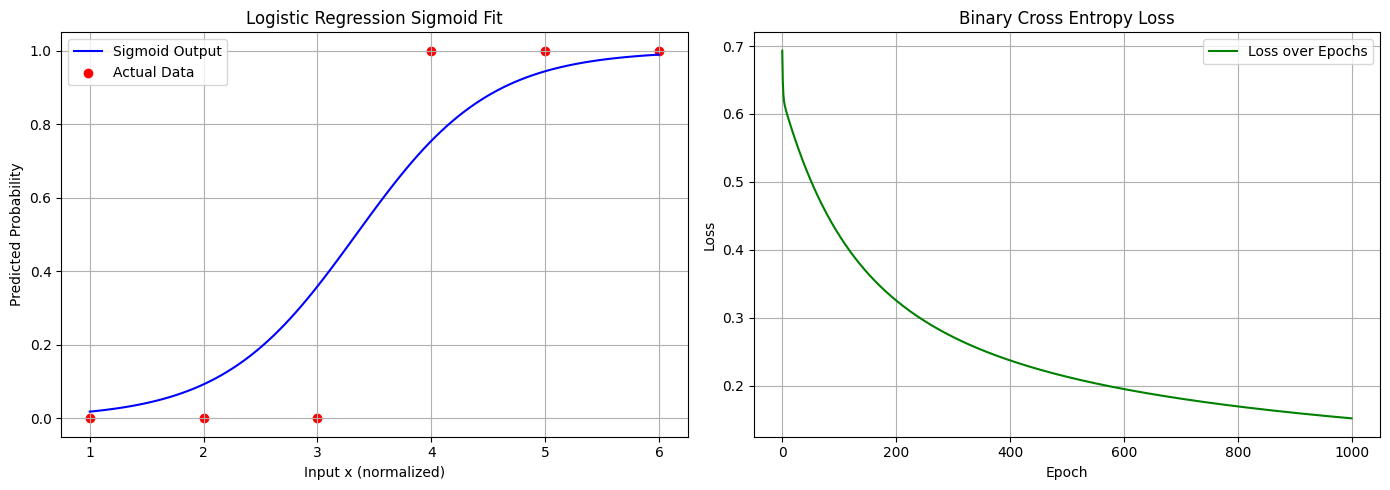

In [10]:
# Step 6: Plot sigmoid prediction curve
plt.figure(figsize=(14, 5))

# Plot 1: Sigmoid output over input
plt.subplot(1, 2, 1)
x_plot = np.linspace(min(x), max(x), 100)
y_plot = predict(x_plot, w1, w0)
plt.plot(x_plot, y_plot, label='Sigmoid Output', color='blue')
plt.scatter(x, y, color='red', label='Actual Data')
plt.title("Logistic Regression Sigmoid Fit")
plt.xlabel("Input x (normalized)")
plt.ylabel("Predicted Probability")
plt.legend()
plt.grid(True)

# Plot 2: Loss over training epochs
plt.subplot(1, 2, 2)
plt.plot(losses, label='Loss over Epochs', color='green')
plt.title("Binary Cross Entropy Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()